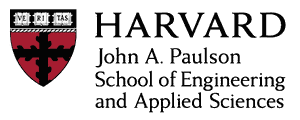

# CS1090A Introduction to Data Science
## Milestone 2: Data Wrangling and Project Redefinition
### MovieLens 1M: getting, understanding and cleaning the data

**Harvard University**<br/>
**Fall 2026**<br/>
**Instructors**: Pavlos Protopapas, Kevin Rader, and Chris Gumb<br/>
**TF mentor**: Sukanya Krishna<br/>
**Canvas project group 34**: Thanh Phong Le, Myra Puruganan and Sandra Palomo

<hr style="height:2.4pt">

This notebook only orchestrates: every computation is a pure, tested function in `scripts/wrangling.py`, the raw files are only read, and no step is random, so there is no seed to set and every run reproduces the same numbers.

In [ ]:
import json
import os
import sys
from collections import Counter
from pathlib import Path

In [ ]:
# The logic lives in scripts/: each step below is a tested function there.
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import wrangling

In [ ]:
DATA = Path(os.environ["MS2_DATA"])
TABLES = ("ratings.dat", "users.dat", "movies.dat")
RESULTS = Path(os.environ["MS2_RESULTS"])
TRAINING_FRACTION = 0.8
results: dict[str, object] = {}
figures: list[dict[str, str]] = []
summary: list[tuple[str, str, str]] = []


def record(ax: plt.Axes, alt: str) -> None:
    """Keep the figure's labels, and show it with its alternative text."""
    labels = {
        "title": ax.get_title(),
        "xlabel": ax.get_xlabel(),
        "ylabel": ax.get_ylabel(),
    }
    figures.append(labels)
    display(ax.figure, metadata={"image/png": {"alt": alt}})
    plt.close(ax.figure)

# Getting the data

The data is MovieLens 1M from GroupLens, https://files.grouplens.org/datasets/movielens/ml-1m.zip. The repository's `data:fetch` task downloads it, checks the MD5 GroupLens publishes, verifies its SHA-256 against the reviewed pin in `contracts/data-pin.toml` and unpacks it; this notebook reads that verified copy and never writes to it. The data's total size, the three verified files together, is reported in megabytes, a megabyte being one million bytes.

In [ ]:
size = sum(wrangling.size_megabytes(DATA / name) for name in TABLES)
results["size_megabytes"] = size
ratings = wrangling.read_ratings(DATA / "ratings.dat")
users = wrangling.read_users(DATA / "users.dat")
movies = wrangling.read_movies(DATA / "movies.dat")
print(f"Data size, the three files together: {size:.2f} MB")

# Understanding the data

One row of `ratings.dat` is one rating: one user's star rating, from 1 to 5, of one movie at one time, in Unix seconds. One row of `users.dat` is one user: gender, an age bucket code, an occupation code and a zip code. One row of `movies.dat` is one movie: its title and its pipe-separated genres. Every column is an integer except gender, zip code, title and genres, which are text.

The usable table is the ratings joined to their user and their movie: one row per rating, ten columns, `user_id`, `movie_id`, `rating`, `timestamp`, `gender`, `age`, `occupation`, `zip_code`, `title` and `genres`. Below are each table's shape, each numerical column's count, mean, minimum and maximum, and the period the ratings cover as UTC dates.

In [ ]:
results["tables"] = {
    "ratings": [len(ratings), 4],
    "users": [len(users), 5],
    "movies": [len(movies), 3],
}
columns = {
    "rating": tuple(r.rating for r in ratings),
    "timestamp": tuple(r.timestamp for r in ratings),
    "age": tuple(u.age for u in users),
    "occupation": tuple(u.occupation for u in users),
}
summaries = {}
for name, values in columns.items():
    summaries[name] = vars(wrangling.summarize(values))
results["summaries"] = summaries
for table, (rows, width) in results["tables"].items():
    print(f"{table}.dat: {rows:,} rows x {width} columns")
for name, s in summaries.items():
    if name == "timestamp":
        continue
    line = f"{name}: count {s['count']:,}, mean {s['mean']:.2f}"
    print(f"{line}, minimum {s['minimum']}, maximum {s['maximum']}")
first = wrangling.utc_date(summaries["timestamp"]["minimum"])
last = wrangling.utc_date(summaries["timestamp"]["maximum"])
print(f"The ratings run from {first} to {last} (UTC).")
kinds = [
    ("user_id", "integer", "the user who rated"),
    ("movie_id", "integer", "the movie rated"),
    ("rating", "integer", "the star rating, 1 to 5: the response"),
    ("timestamp", "integer", "when the rating was made, Unix seconds"),
    ("gender", "text", "F or M, self-reported"),
    ("age", "integer", "an age bucket code: 1, 18, 25, 35, 45, 50, 56"),
    ("occupation", "integer", "an occupation code, 0 to 20"),
    ("zip_code", "text", "the zip code as given"),
    ("title", "text", "the movie's title and year"),
    ("genres", "text", "the movie's pipe-separated genres"),
]
types = ["| Column | Type | Meaning |", "| --- | --- | --- |"]
for column, kind, meaning in kinds:
    types.append(f"| `{column}` | {kind} | {meaning} |")
display(Markdown("\n".join(types)))

In [ ]:
per_user = wrangling.ratings_per_user(ratings)
per_movie = Counter(r.movie_id for r in ratings)
fewest = min(per_user.values())
print(f"{len(per_user):,} users rated, each at least {fewest} times")
print(f"{len(per_movie):,} movies were rated at least once")
fig, ax = plt.subplots()
ax.hist(list(per_user.values()), bins=50, log=True)
ax.set_title("Ratings per user")
ax.set_xlabel("Ratings made by one user")
ax.set_ylabel("Number of users (log scale)")
record(
    ax,
    f"Histogram of ratings per user, log scale: {len(per_user):,} users",
)
fig, ax = plt.subplots()
ax.hist(list(per_movie.values()), bins=50, log=True)
ax.set_title("Ratings per movie")
ax.set_xlabel("Ratings received by one movie")
ax.set_ylabel("Number of movies (log scale)")
record(
    ax,
    f"Histogram of ratings per movie, log scale: {len(per_movie):,} movies",
)

# Cleaning and preprocessing

Each check below prints its finding from the data and states the decision taken. The ratings are also judged by the `ratings-quality/v1` contract: validity, uniqueness, referential integrity and completeness, each pass, fail or unknown with the count it found.

## Missing data

Empty fields are counted per column of all three files on the raw text, before any field is parsed, and the users with a gap are counted per gender to see whether missingness follows a group.

Decision: nothing is imputed. A rating row with an empty field cannot be used and is excluded and counted; an empty demographic field stays empty and is treated as unknown, because the MovieLens README says the demographics were given voluntarily and not checked.

In [ ]:
names = {
    "ratings.dat": ("user_id", "movie_id", "rating", "timestamp"),
    "users.dat": wrangling.USER_COLUMNS,
    "movies.dat": ("movie_id", "title", "genres"),
}
missing = {}
for table, cols in names.items():
    missing[table] = wrangling.missing_by_column(DATA / table, cols)
    print(f"{table}: {missing[table]}")
results["missing_by_column"] = missing
by_gender = wrangling.missing_by_group(
    DATA / "users.dat",
    wrangling.USER_COLUMNS,
    "gender",
)
results["missing_by_gender"] = by_gender
empty = sum(sum(counts.values()) for counts in missing.values())
print(f"Missing data finding: {empty} empty fields in the three files")
print(f"users with a gap, by gender: {by_gender}")
summary.append(("Missing data", f"{empty} empty fields", "nothing imputed"))

## Unusual values

Ratings are checked against the 1 to 5 scale and against the users and movies tables; demographic values against the domains the README documents: gender M or F, seven age codes, occupations 0 to 20, and five-digit zip codes.

Decision: a rating outside 1 to 5, a repeated user and movie pair, or a rating whose user or movie is unknown is an error, excluded and counted. A zip code that is not five digits, such as a ZIP+4 or a foreign code, is a real self-reported value: it is kept as text and not used as a numerical feature.

In [ ]:
quality = wrangling.judge(ratings, users, movies)
results["quality"] = [vars(rule) for rule in quality.rules]
unusual = wrangling.unusual_users(users)
results["unusual_users"] = unusual
for rule in quality.rules:
    print(f"{rule.name} ({rule.kind}): {rule.status}, {rule.count} found")
for rule_name, count in unusual.items():
    print(f"{rule_name}: {count}")
broken = sum(rule.count for rule in quality.rules)
zips = unusual["zip-not-five-digits"]
print(f"Unusual values finding: {broken} rating errors, {zips} odd zip codes")
summary.append(
    (
        "Unusual values",
        f"{broken} rating errors; {zips} zip codes not five digits",
        "errors excluded; zip codes kept as text",
    ),
)

## Class balance

The response is the star rating, so each of its five classes is counted, with its share, including any that is empty.

Decision: the rating is treated as a number on the 1 to 5 scale and evaluated by root-mean-square error; because the low stars are the rarest, Milestone 3 also reports the error per star, so that a model cannot look good by predicting only the common stars.

In [ ]:
balance = wrangling.rating_balance(ratings)
results["rating_balance"] = balance
total = sum(balance.values())
shares = {star: count / total for star, count in balance.items()}
for star, count in balance.items():
    print(f"{star}-star: {count:,} ratings ({shares[star]:.1%})")
rarest = min(balance, key=balance.__getitem__)
print(f"Class balance finding: the {rarest}-star class is the rarest")
summary.append(
    (
        "Class balance",
        f"{rarest}-star is {shares[rarest]:.1%} of ratings",
        "regression target: RMSE overall and per star",
    ),
)
fig, ax = plt.subplots()
ax.bar([str(star) for star in balance], list(balance.values()))
ax.set_title("Ratings per star")
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of ratings")
record(
    ax,
    f"Bar chart of ratings per star; the {rarest}-star class is the rarest",
)

## Scale of the features

Each numerical column's minimum and maximum are printed below; the timestamp is shown above as dates.

Decision: age and occupation are codes for categories, not quantities, so they are one-hot encoded rather than scaled; the timestamp only orders and splits the ratings; any numerical feature built in Milestone 3 is standardized with the training set's mean and standard deviation only, so that no scale is learned from test data.

In [ ]:
ranges = {}
for name, s in summaries.items():
    ranges[name] = (s["minimum"], s["maximum"])
    print(f"{name}: {s['minimum']} to {s['maximum']}")
low, high = ranges["rating"]
print(f"Scale of the features finding: {len(ranges)} numerical columns")
summary.append(
    (
        "Scale of the features",
        f"rating {low} to {high}; ratings dated {first} to {last}",
        "codes one-hot; numbers standardized on training only",
    ),
)

## Information leakage

The ratings are split at one absolute time point, the timestamp below which the training fraction (80 percent) of ratings fall, before any feature is computed, so no training rating comes after a test rating. A user's mean over all ratings is refused, because it would use ratings recorded after the ones it is meant to predict. The split is then audited, as 2026 recommender evaluation practice asks: the test ratings whose user, or whose movie, never appears in training are counted.

Decision: every feature is computed from training ratings only; no column is recorded after the rating it would predict; and each test rating is put in one bucket by its training history: warm, new user, new movie or both new. Because a new user still rates movies seen in training, it is predicted by the movie's training mean, the global training mean being the fallback only for a new movie; the error is reported for each bucket as well as overall.

In [ ]:
cutoff = wrangling.time_cutoff(ratings, TRAINING_FRACTION)
split = wrangling.split_at(ratings, cutoff)
try:
    wrangling.user_means(ratings, cutoff)
    refused = False
except wrangling.LeakageError:
    refused = True
results["leakage_refused"] = refused
results["split"] = {
    "cutoff": cutoff,
    "train": len(split.train),
    "test": len(split.test),
    "train_latest": max(r.timestamp for r in split.train),
    "test_earliest": min(r.timestamp for r in split.test),
}
cold = wrangling.cold_start(split)
results["cold_start"] = cold
buckets = wrangling.test_buckets(split)
results["test_buckets"] = buckets
for bucket, count in buckets.items():
    print(f"{bucket}: {count:,} test ratings ({count / len(split.test):.1%})")
day = wrangling.utc_date(cutoff)
print(f"Information leakage finding: the split falls on {day} (UTC)")
print(f"{len(split.train):,} training and {len(split.test):,} test ratings")
print(f"a mean over all ratings is refused: {refused}")
print(f"cold start: {cold['user-unseen']:,} of {cold['test']:,} test ratings")
print(f"have an unseen user, {cold['movie-unseen']:,} an unseen movie")
summary.append(
    (
        "Information leakage",
        f"split on {day}; {cold['user-unseen']:,} test ratings by new users",
        "features from training only",
    ),
)
year = 365.25 * 24 * 3600
fig, ax = plt.subplots()
ax.hist([1970 + r.timestamp / year for r in ratings], bins=50)
ax.axvline(1970 + cutoff / year, color="black", label="split")
ax.set_title("Ratings over time, split at one time point")
ax.set_xlabel("Rating time (year)")
ax.set_ylabel("Number of ratings")
ax.legend()
record(
    ax,
    f"Histogram of ratings over time, with the split marked on {day}",
)

# Data wrangling summary

The usable table is the ratings joined to their user and movie, after the checks above; its rows and columns are computed below. Following 2026 data-preparation practice, the data was audited before the split (missing values per column and by group, values against their documented domains, class balance, feature ranges) and after it (leakage and cold-start exposure), and every decision is recorded with the finding that led to it. The table answers, in the brief's order, each data-wrangling question the brief asks: the source and size, what one row is, the shape, the types, the summary statistics, each cleaning check, the cold start that changes the plan, the usable table and the question. Every finding is this run's own number.

In [ ]:
joined = wrangling.joined_shape(ratings, users, movies)
results["joined_table"] = list(joined)
print(f"The joined table: {joined[0]:,} rows x {joined[1]} columns")
rows = ["| Check | Finding | Decision |", "| --- | --- | --- |"]
tables = results["tables"]
shape = ", ".join(f"{t} {n:,} x {w}" for t, (n, w) in tables.items())
texts = sum(kind == "text" for _, kind, _ in kinds)
typed = f"{len(kinds) - texts} integer and {texts} text columns"
mean = summaries["rating"]["mean"]
gaps = f"F {by_gender.get('F', 0)}, M {by_gender.get('M', 0)}"
share = cold["user-unseen"] / cold["test"]
new_users = f"{share:.1%} of test ratings by new users"
new_movies = f"{cold['movie-unseen']:,} by new movies"
kept = "no row removed" if broken == 0 else f"{broken} rows removed"
opening = [
    (
        "Source and size",
        f"MovieLens 1M (GroupLens), {size:.2f} MB, digest verified",
        "read the verified copy; never modified",
    ),
    (
        "One row",
        "one user's star rating of one movie at one time",
        "the star rating is the response",
    ),
    ("Shape", shape, "joined on user_id and movie_id"),
    ("Columns and types", typed, "codes treated as categories"),
    (
        "Summary statistics",
        f"rating mean {mean:.2f} on 1 to 5; dated {first} to {last}",
        "times shown as dates",
    ),
    (
        "Missing data pattern",
        f"users with a gap by gender: {gaps}",
        "no group is affected",
    ),
]
closing = [
    (
        "Cold start",
        f"{new_users}; {new_movies}",
        "new users get the movie's mean; RMSE per bucket",
    ),
    (
        "Usable table",
        f"{joined[0]:,} rows x {joined[1]} columns after cleaning",
        kept,
    ),
    (
        "Project question",
        "test RMSE against the training-mean baseline",
        "answered at the end, overall and per bucket",
    ),
]
for check, finding, decision in opening + summary + closing:
    rows.append(f"| {check} | {finding} | {decision} |")
display(Markdown("\n".join(rows)))

# Project question

Revised question: using only the ratings recorded before one time point, the 80th percentile of rating times, can a model predict the star rating of each later rating with a lower root-mean-square error than the baseline that predicts the training ratings' mean? At the end of the project the question is answered by comparing the two errors on the later ratings, overall and in each bucket: warm, new user, new movie and both new.

In [ ]:
results["figures"] = figures
text = json.dumps(results, indent=2, default=str)
RESULTS.write_text(text, encoding="utf-8")
print(f"Results recorded in {RESULTS}")